In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
os.chdir('/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac6-CHIPOMPO')
CWD_PATH = os.getcwd()
print(CWD_PATH)

/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac6-CHIPOMPO


## Task 2. Track through occlusion with a Kalman filter



In [ ]:
##############################################
# COLAB SETUP
##############################################
#!pip install -q opencv-contrib-python
#!pip uninstall -y opencv-python opencv-python-headless
#!pip uninstall opencv-python opencv-contrib-python opencv-python-headless -y
!pip install opencv-contrib-python
import cv2
import csv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Video, Image, display

Frame size       : 360 x 640
Requested ROI    : (140, 260, 80, 80)
Tracker object   : < cv2.legacy.TrackerCSRT 0x7b0882bfb590>
Tracker initialised (CSRT) on ROI (140, 260, 80, 80) (init returned True)
VideoWriter opened with codec: mp4v
CSV saved: videos/kalman_results/tracking_results.csv


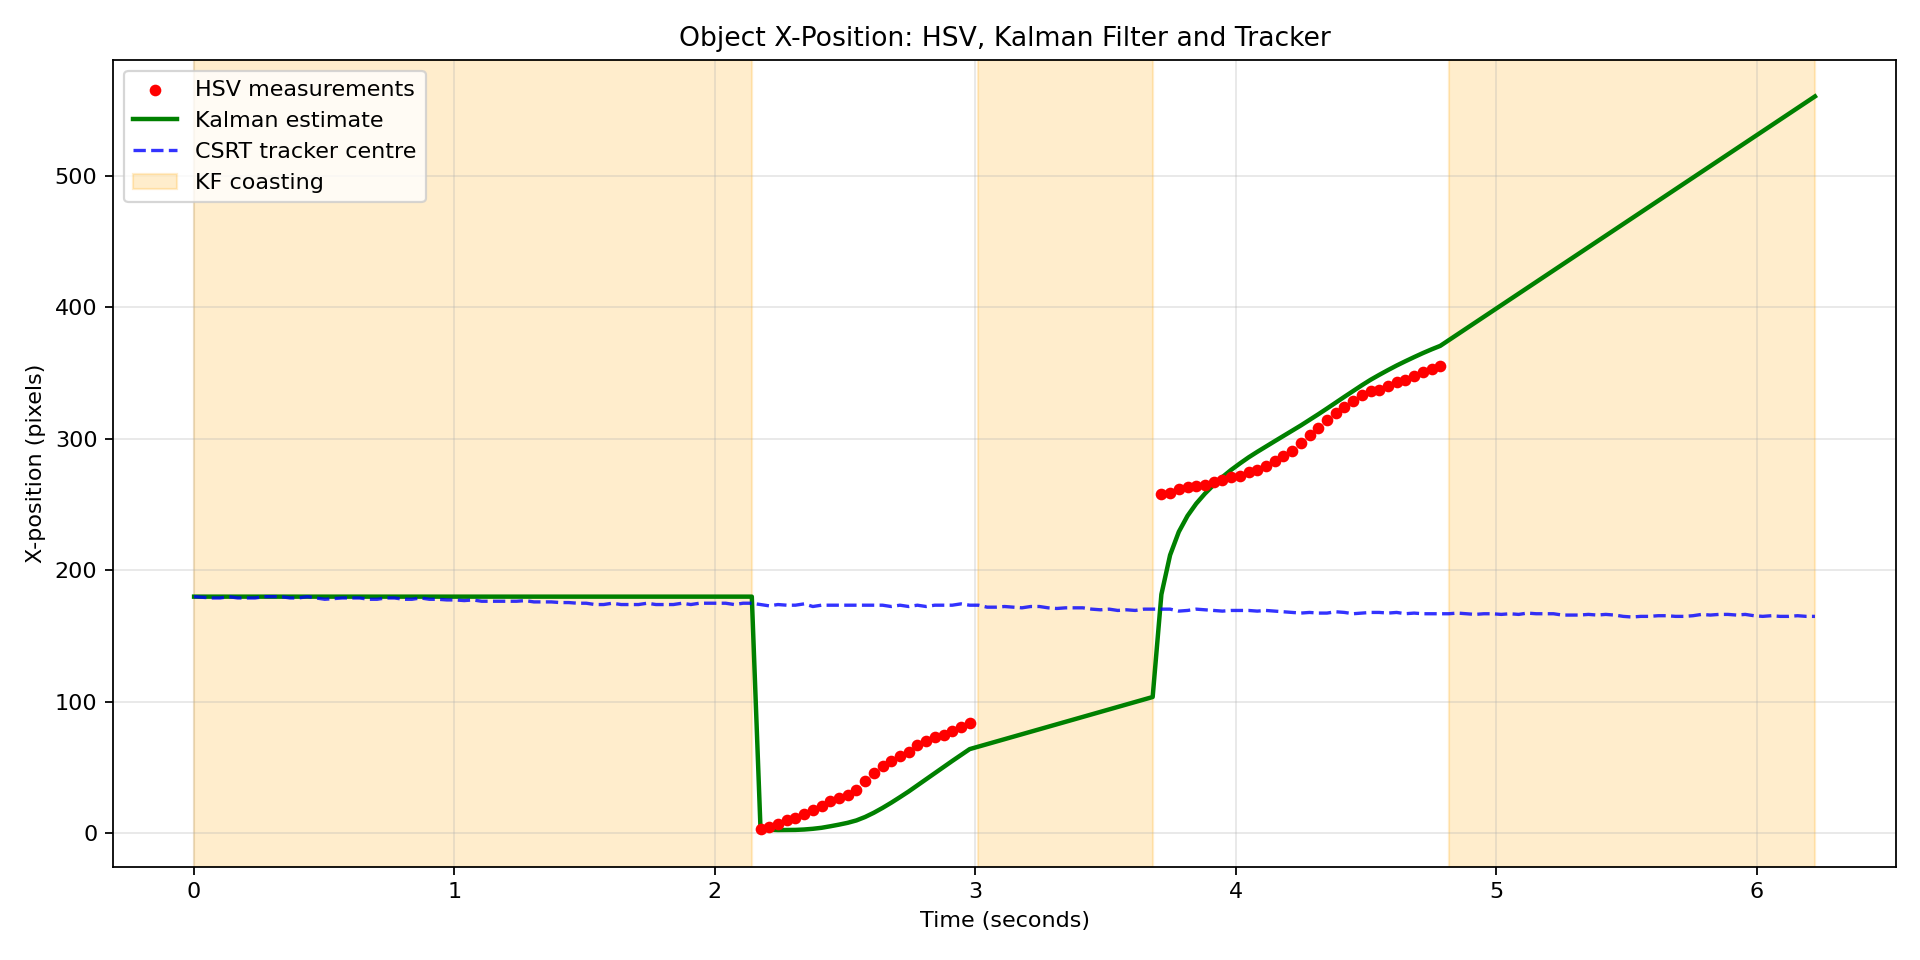


Processing complete.
Output folder  : /content/drive/MyDrive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac6-CHIPOMPO/videos/kalman_results
Annotated video: annotated_tracking.mp4
Position plot  : x_position_plot.png
CSV results    : tracking_results.csv


In [ ]:

##############################################
# CONFIGURATION
##############################################

VIDEO_PATH = "videos/rolling_ball.mp4"

OUTPUT_DIR = Path("videos/kalman_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# "CSRT" or "KCF"
TRACKER_TYPE = "CSRT"

# Kalman tuning parameters
PROCESS_NOISE_ACCEL_STD = 80.0
MEASUREMENT_NOISE_STD   = 15.0

# Use None to rely on natural occlusion in the video.
FORCE_OCCLUSION = None       # e.g. (100, 140)

# Ignore very small colour blobs
MIN_CONTOUR_AREA = 100

##############################################
# HARD-CODED HSV RANGE  (adjust for your ball's colour)
# Default: generous red range. Tune with the picker below.
##############################################
lower_hsv = np.array([0,   100, 100], dtype=np.uint8)
upper_hsv = np.array([179, 255, 255], dtype=np.uint8)

##############################################
# HARD-CODED INITIAL ROI  (x, y, w, h)
# Frame is 360 wide × 640 tall, so:
#   x + w <= 360
#   y + h <= 640
##############################################
INITIAL_ROI = (140, 260, 80, 80)     # (x, y, w, h)


##############################################
# HELPER FUNCTIONS
##############################################

def create_tracker(tracker_type):
    """
    Return a tracker that initialises reliably.

    In OpenCV >=4.13 the non-legacy CSRT/KCF init() returns None on
    success (not True), which breaks `if not tracker.init(...)`.
    Prefer the legacy API, which returns proper True/False.
    """
    name = tracker_type.upper()

    legacy = getattr(cv2, "legacy", None)
    if legacy is not None:
        if name == "CSRT" and hasattr(legacy, "TrackerCSRT_create"):
            return legacy.TrackerCSRT_create()
        if name == "KCF" and hasattr(legacy, "TrackerKCF_create"):
            return legacy.TrackerKCF_create()

    # Fallback: modern API.
    if name == "CSRT" and hasattr(cv2, "TrackerCSRT_create"):
        return cv2.legacy.TrackerCSRT_create()
    if name == "KCF" and hasattr(cv2, "TrackerKCF_create"):
        return cv2.TrackerKCF_create()

    raise RuntimeError(
        f"{name} tracker is unavailable. Install opencv-contrib-python."
    )


def detect_largest_colour_object(frame, lower, upper):
    """
    Detect the largest HSV colour contour.
    Return centroid (x, y), bounding box and mask.
    Return None for the centroid when no suitable contour exists.
    """
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, lower, upper)

    kernel = np.ones((5, 5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    if not contours:
        return None, None, mask

    contour = max(contours, key=cv2.contourArea)
    if cv2.contourArea(contour) < MIN_CONTOUR_AREA:
        return None, None, mask

    moments = cv2.moments(contour)
    if moments["m00"] == 0:
        return None, None, mask

    cx = int(moments["m10"] / moments["m00"])
    cy = int(moments["m01"] / moments["m00"])

    bbox = cv2.boundingRect(contour)
    return (cx, cy), bbox, mask


##############################################
# INTERACTIVE HSV PICKER VIA ipywidgets
# Uncomment and run to tune lower_hsv / upper_hsv from frame 1.
##############################################
"""
import ipywidgets as widgets

_cap = cv2.VideoCapture(VIDEO_PATH)
_ret, _frame = _cap.read()
_cap.release()
_hsv = cv2.cvtColor(_frame, cv2.COLOR_BGR2HSV)

def _pick(hlo, hhi, slo, shi, vlo, vhi):
    _lower = np.array([hlo, slo, vlo], dtype=np.uint8)
    _upper = np.array([hhi, shi, vhi], dtype=np.uint8)
    _mask = cv2.inRange(_hsv, _lower, _upper)
    _overlay = cv2.bitwise_and(_frame, _frame, mask=_mask)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].imshow(cv2.cvtColor(_frame, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(cv2.cvtColor(_overlay, cv2.COLOR_BGR2RGB))
    axes[1].set_title("HSV mask"); axes[1].axis("off")
    plt.tight_layout(); plt.show()

    print(f"lower_hsv = np.array([{hlo}, {slo}, {vlo}], dtype=np.uint8)")
    print(f"upper_hsv = np.array([{hhi}, {shi}, {vhi}], dtype=np.uint8)")

widgets.interact(
    _pick,
    hlo=widgets.IntSlider(0,   0, 179, 1),
    hhi=widgets.IntSlider(179, 0, 179, 1),
    slo=widgets.IntSlider(70,  0, 255, 1),
    shi=widgets.IntSlider(255, 0, 255, 1),
    vlo=widgets.IntSlider(50,  0, 255, 1),
    vhi=widgets.IntSlider(255, 0, 255, 1),
)
"""


##############################################
# CONSTANT-VELOCITY KALMAN FILTER
# State: [x, y, vx, vy];  Measurement: [x, y]
##############################################

class ConstantVelocityKalman:

    def __init__(
        self,
        x,
        y,
        fps,
        process_accel_std=80.0,
        measurement_std=15.0
    ):
        self.dt = 1.0 / max(fps, 1e-6)

        self.state = np.array(
            [[float(x)], [float(y)], [0.0], [0.0]],
            dtype=np.float64
        )

        dt = self.dt

        self.F = np.array([
            [1, 0, dt, 0],
            [0, 1, 0, dt],
            [0, 0, 1, 0],
            [0, 0, 0, 1]
        ], dtype=np.float64)

        self.H = np.array([
            [1, 0, 0, 0],
            [0, 1, 0, 0]
        ], dtype=np.float64)

        self.P = np.diag([
            25.0**2,
            25.0**2,
            200.0**2,
            200.0**2
        ])

        q = process_accel_std**2

        self.Q = q * np.array([
            [dt**4 / 4, 0, dt**3 / 2, 0],
            [0, dt**4 / 4, 0, dt**3 / 2],
            [dt**3 / 2, 0, dt**2, 0],
            [0, dt**3 / 2, 0, dt**2]
        ], dtype=np.float64)

        self.R = np.eye(2) * measurement_std**2
        self.I = np.eye(4)

    def predict(self):
        self.state = self.F @ self.state
        self.P = self.F @ self.P @ self.F.T + self.Q
        return self.position()

    def update(self, measurement):
        z = np.array(
            [[float(measurement[0])],
             [float(measurement[1])]],
            dtype=np.float64
        )

        innovation = z - self.H @ self.state
        S = self.H @ self.P @ self.H.T + self.R
        K = self.P @ self.H.T @ np.linalg.inv(S)

        self.state = self.state + K @ innovation

        A = self.I - K @ self.H
        self.P = A @ self.P @ A.T + K @ self.R @ K.T

    def position(self):
        return (
            float(self.state[0, 0]),
            float(self.state[1, 0])
        )


##############################################
# TRACKER INITIALISATION (ROI validated + legacy API)
##############################################

cap = cv2.VideoCapture(VIDEO_PATH)
if not cap.isOpened():
    raise FileNotFoundError(VIDEO_PATH)

fps = cap.get(cv2.CAP_PROP_FPS)
if fps <= 0:
    fps = 25.0

width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

ret, first_frame = cap.read()
if not ret:
    cap.release()
    raise ValueError("Could not read the first frame.")

# Validate ROI
x, y, w, h = map(int, INITIAL_ROI)

print(f"Frame size       : {width} x {height}")
print(f"Requested ROI    : {(x, y, w, h)}")

if not (0 <= x < width and 0 <= y < height):
    cap.release()
    raise ValueError(
        f"ROI origin ({x},{y}) outside {width}x{height} frame."
    )
if w <= 0 or h <= 0:
    cap.release()
    raise ValueError(f"ROI size must be positive, got ({w}x{h}).")
if x + w > width or y + h > height:
    cap.release()
    raise ValueError(
        f"ROI ({x},{y},{w},{h}) extends past frame edge "
        f"({width}x{height}). Need x+w<={width} and y+h<={height}."
    )

roi = (x, y, w, h)
initial_centre = (x + w / 2.0, y + h / 2.0)

# Kalman
kalman = ConstantVelocityKalman(
    initial_centre[0],
    initial_centre[1],
    fps,
    PROCESS_NOISE_ACCEL_STD,
    MEASUREMENT_NOISE_STD
)

# Tracker
tracker = create_tracker(TRACKER_TYPE)
print(f"Tracker object   : {tracker!r}")

init_result = tracker.init(first_frame, roi)

# Legacy API returns True/False. Modern 4.13+ API returns None on
# success. Treat only an explicit False as failure.
if init_result is False:
    cap.release()
    raise RuntimeError(
        f"{TRACKER_TYPE}.init() failed on ROI {roi} "
        f"for a {width}x{height} frame."
    )

print(f"Tracker initialised ({TRACKER_TYPE}) on ROI {roi} "
      f"(init returned {init_result!r})")


##############################################
# Video writer (Colab-safe with fallback codec)
##############################################
output_video_path = OUTPUT_DIR / "annotated_tracking.mp4"

def _make_writer(path, fps, size):
    for fourcc_str in ("mp4v", "avc1", "XVID"):
        fourcc = cv2.VideoWriter_fourcc(*fourcc_str)
        w_ = cv2.VideoWriter(str(path), fourcc, fps, size)
        if w_.isOpened():
            print(f"VideoWriter opened with codec: {fourcc_str}")
            return w_
        w_.release()
    raise RuntimeError("Could not create annotated video with any codec.")

writer = _make_writer(output_video_path, fps, (width, height))

# Rewind and process every frame consistently.
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

frame_index = 0
records = []


##############################################
# MAIN PROCESSING LOOP  (headless)
##############################################

while True:
    ret, frame = cap.read()
    if not ret:
        break

    frame_index += 1

    measurement, detection_bbox, mask = detect_largest_colour_object(
        frame, lower_hsv, upper_hsv
    )

    forced_occlusion = (
        FORCE_OCCLUSION is not None
        and FORCE_OCCLUSION[0] <= frame_index <= FORCE_OCCLUSION[1]
    )
    if forced_occlusion:
        measurement = None

    # Predict every frame.
    kalman.predict()

    if measurement is not None:
        mx, my = measurement
        cv2.circle(frame, (mx, my), 7, (0, 0, 255), -1)
        cv2.putText(
            frame, "HSV measurement", (mx + 8, my - 8),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2
        )
        kalman.update(measurement)
    else:
        cv2.putText(
            frame, "NO HSV DETECTION - KF COASTING",
            (10, 65),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 165, 255), 2
        )

    kf_x, kf_y = kalman.position()
    kx, ky = int(round(kf_x)), int(round(kf_y))

    cv2.circle(frame, (kx, ky), 7, (0, 255, 0), 2)
    cv2.putText(
        frame, "Kalman estimate", (kx + 8, ky + 18),
        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2
    )

    #Tracker update (robust to OpenCV 4.14 quirks)
    update_result = tracker.update(frame)

    if isinstance(update_result, tuple) and len(update_result) == 2:
        tracker_ok, tracker_bbox = update_result
        tracker_ok = bool(tracker_ok) and tracker_bbox is not None
    else:
        # Fallback: some builds return a bare bbox or None.
        tracker_ok = update_result is not None and update_result is not False
        tracker_bbox = update_result if tracker_ok else (0, 0, 0, 0)

    if tracker_ok:
        tx, ty, tw, th = map(int, tracker_bbox)
        cv2.rectangle(
            frame, (tx, ty), (tx + tw, ty + th),
            (255, 0, 0), 2
        )
        cv2.putText(
            frame, TRACKER_TYPE,
            (tx, max(20, ty - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2
        )
    else:
        cv2.putText(
            frame, f"{TRACKER_TYPE}: TRACK LOST",
            (10, 95),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2
        )

    is_coasting = measurement is None

    cv2.putText(
        frame, f"Frame: {frame_index}",
        (10, 30),
        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2
    )

    writer.write(frame)

    records.append({
        "frame": frame_index,
        "time_seconds": (frame_index - 1) / fps,
        "measurement_x": (
            measurement[0] if measurement is not None else np.nan
        ),
        "measurement_y": (
            measurement[1] if measurement is not None else np.nan
        ),
        "estimate_x": kf_x,
        "estimate_y": kf_y,
        "coasting": is_coasting,
        "tracker_success": bool(tracker_ok),
        "tracker_x": (
            tracker_bbox[0] + tracker_bbox[2] / 2
            if tracker_ok else np.nan
        )
    })

cap.release()
writer.release()


##############################################
# SAVE CSV RESULTS
##############################################

csv_path = OUTPUT_DIR / "tracking_results.csv"

if records:
    with open(csv_path, "w", newline="", encoding="utf-8") as file:
        fieldnames = list(records[0].keys())
        csv_writer = csv.DictWriter(file, fieldnames=fieldnames)
        csv_writer.writeheader()
        csv_writer.writerows(records)
    print(f"CSV saved: {csv_path}")
else:
    print("No records to write.")


##############################################
# PLOT X-POSITION OVER TIME
##############################################

if records:
    times          = np.array([r["time_seconds"] for r in records])
    measurements_x = np.array([r["measurement_x"] for r in records])
    estimates_x    = np.array([r["estimate_x"]    for r in records])
    tracker_x      = np.array([r["tracker_x"]     for r in records])
    coasting       = np.array([r["coasting"]      for r in records],
                              dtype=bool)

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.scatter(
        times, measurements_x,
        s=18, color="red",
        label="HSV measurements", zorder=3
    )
    ax.plot(
        times, estimates_x,
        color="green", linewidth=2,
        label="Kalman estimate"
    )
    ax.plot(
        times, tracker_x,
        color="blue", linestyle="--", alpha=0.8,
        label=f"{TRACKER_TYPE} tracker centre"
    )

    if coasting.any():
        padded_prev = np.r_[False, coasting[:-1]]
        padded_next = np.r_[coasting[1:], False]
        starts = np.where(coasting & ~padded_prev)[0]
        ends   = np.where(coasting & ~padded_next)[0]

        for i, (start, end) in enumerate(zip(starts, ends)):
            ax.axvspan(
                times[start], times[end],
                color="orange", alpha=0.2,
                label="KF coasting" if i == 0 else None
            )

    ax.set_title("Object X-Position: HSV, Kalman Filter and Tracker")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("X-position (pixels)")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()

    plot_path = OUTPUT_DIR / "x_position_plot.png"
    fig.savefig(plot_path, dpi=160)
    plt.close(fig)

    display(Image(filename=str(plot_path)))


##############################################
# DISPLAY ANNOTATED VIDEO INLINE
##############################################

print("\nProcessing complete.")
print("Output folder  :", OUTPUT_DIR.resolve())
print("Annotated video:", output_video_path.name)
print("Position plot  : x_position_plot.png")
print("CSV results    : tracking_results.csv")


**what does each approach do when the object disappears?**</br>
When the object disappears, HSV colour detection simply stops reporting. It evaluates each frame independently, and so as soon as the coloured pixels no longer match the thresholded range, detect_largest_colour_object returns None and no measurement is produced. There is no memory, no extrapolation, and no guess about where the object might be. It signals that the object is not visible.

The Kalman filter keeps going. Because it carries a constant-velocity motion model, it continues to call `predict()` on every frame even without a measurement, propagating the state forward using the last known velocity and inflating its covariance by the process noise Q. This is the coasting behaviour shown by the orange bands and the smooth green line running through the gaps in the plot. It produces a physically plausible trajectory in the absence of the object.

CSRT and KCF behave differently from both HSV and Kalman filter. They have no motion model, so they cannot extrapolate. Instead they keep searching for their learned appearance template and returning a bounding box for as long as the correlation response stays above their internal threshold. In practice this means they usually do not report failure during brief occlusions; they silently drift onto nearby background texture, a shadow, or a similar-looking region, and continue to return True from `update()`. When the object reappears, they often fail to re-lock and either stay stuck on the wrong region or eventually report TRACK LOST. The flat blue line in the plot through every coasting interval is the visual signature of this: CSRT kept returning a position, but it was not tracking the missing object.